# Week 3 · Notebook 1 - Multi-armed bandits

**Story.** Re-Mind can quiz you in 4 styles: MCQ, fill-in-the-blank, true/false, explain-in-your-own-words. Each style has an unknown chance $p_k$ that the quiz actually helps you remember. Every quiz is one *pull* of an *arm*. Goal: get as much learning as possible over 1000 quizzes.

This is RL with **one state**: no consequences, just *which action is best?* It isolates the most important idea in RL: **exploration vs exploitation**.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))   # so we can import the remind package
import random
import matplotlib.pyplot as plt
from remind.rl.bandits import BernoulliBandit, EpsilonGreedy, UCB1, run

## 1. The environment
Each arm returns reward 1 with probability $p_k$, else 0. The agent never sees `probs`.

In [2]:
probs = [0.35, 0.50, 0.70, 0.55]          # MCQ, fill-blank, explain, true/false
bandit = BernoulliBandit(probs, seed=0)
print([bandit.pull(2) for _ in range(10)])

[0.0, 0.0, 1.0, 1.0, 1.0, 1.0, 0.0, 1.0, 1.0, 1.0]


## 2. Estimating values with a running mean
After $n$ pulls of arm $a$, the estimate is the average reward. Incrementally:

$$Q_{n+1}(a) = Q_n(a) + \frac{1}{n}\big(r - Q_n(a)\big)$$

Read it as: *new estimate = old estimate + step size × error*. **This exact shape returns in Q-learning.**

In [3]:
q, n = 0.0, 0
for r in [1, 0, 1, 1, 0]:
    n += 1
    q += (r - q) / n
    print(f'after {n} rewards: estimate = {q:.2f}')

after 1 rewards: estimate = 1.00
after 2 rewards: estimate = 0.50
after 3 rewards: estimate = 0.67
after 4 rewards: estimate = 0.75
after 5 rewards: estimate = 0.60


## 3. Greedy is a trap
A purely greedy agent picks whatever *looks* best so far. If the best arm is unlucky early, it is never tried again.

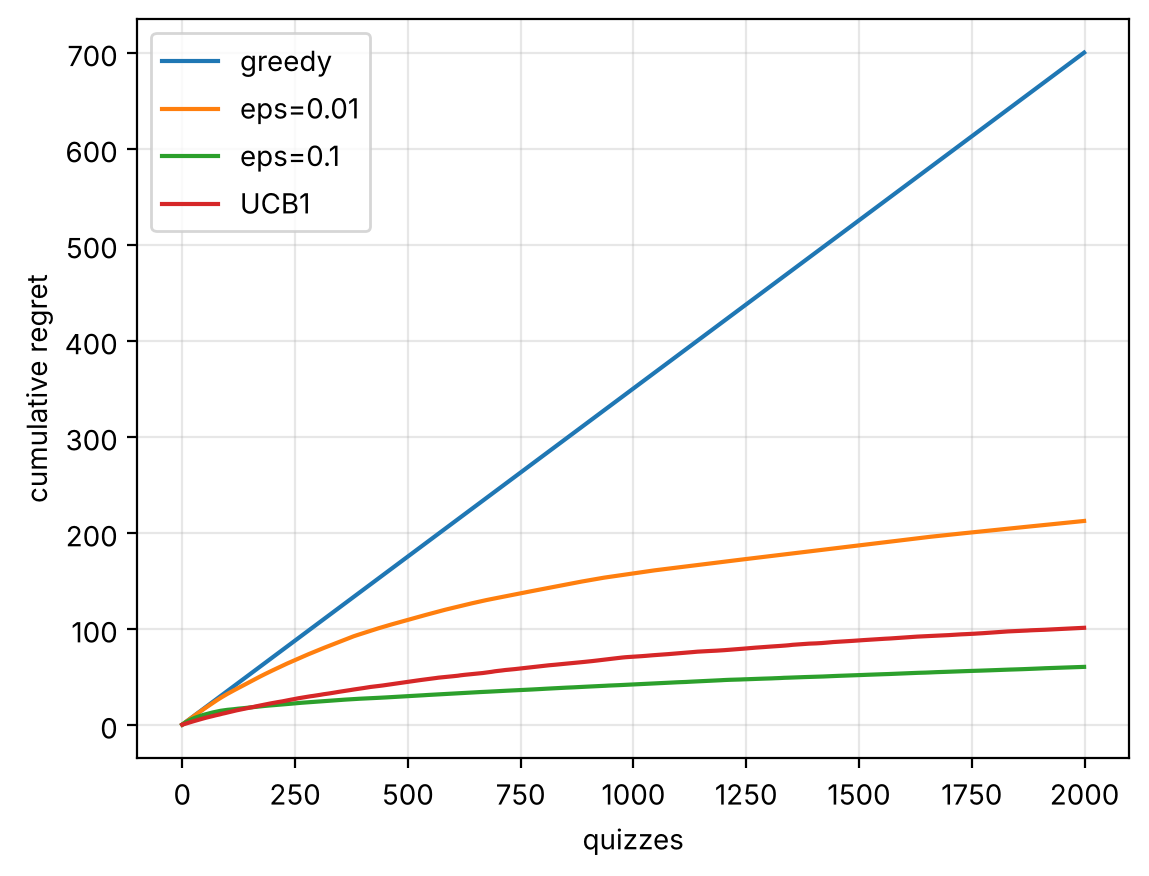

In [4]:
def avg_regret(make_agent, runs=50, steps=2000):
    total = [0.0] * steps
    for i in range(runs):
        _, reg = run(BernoulliBandit(probs, seed=i), make_agent(), steps)
        total = [t + r / runs for t, r in zip(total, reg)]
    return total

for name, mk in [('greedy', lambda: EpsilonGreedy(4, 0.0)),
                 ('eps=0.01', lambda: EpsilonGreedy(4, 0.01)),
                 ('eps=0.1', lambda: EpsilonGreedy(4, 0.1)),
                 ('UCB1', lambda: UCB1(4))]:
    plt.plot(avg_regret(mk), label=name)
plt.xlabel('quizzes'); plt.ylabel('cumulative regret'); plt.legend(); plt.grid(alpha=.3); plt.show()

**Regret** = how much reward we lost compared with always using the best arm. Flat regret = the agent found the best arm.

## 4. UCB: optimism in the face of uncertainty
$$a_t = \arg\max_a \; Q(a) + \sqrt{\frac{c\,\ln t}{N(a)}}$$
Rarely tried arms get a bonus, so the agent explores *where it is unsure*, not at random.

In [5]:
agent = UCB1(4, seed=0)
run(BernoulliBandit(probs, seed=0), agent, 2000)
for style, n, v in zip(['MCQ', 'fill-blank', 'explain', 'T/F'], agent.counts, agent.values):
    print(f'{style:11s} used {n:5d} times, estimated p = {v:.2f}')

MCQ         used    54 times, estimated p = 0.26
fill-blank  used   175 times, estimated p = 0.50
explain     used  1465 times, estimated p = 0.69
T/F         used   306 times, estimated p = 0.57


## ✍️ Exercises (submit this notebook)
1. Change `probs` so two arms are very close (0.70 vs 0.68). Which algorithm suffers more? Why?
2. Implement **decaying ε** ($\varepsilon_t = 1/\sqrt{t}$) as a new class and add it to the plot.
3. *Non-stationary bandit:* after 1000 steps swap the best and worst arm. Replace the running mean by a constant step size $\alpha=0.1$ and show it adapts.
4. In 3-4 lines: how could the real Re-Mind tutor use a bandit? What would the reward be?